# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yafet Getachew, Mofeoluwa Akande, Grady Berlik, Eyram Golo

**Date:** 11/2/26

##Q1:

In [ ]:
# Download + unzip data zip file
!wget -q -O data.zip https://github.com/sds3001/L01-cv/raw/main/data.zip
!unzip -q -o data.zip

In [ ]:
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

##Q2:

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("X_train[i] shape:", X_train[0].shape)
print("X_test[i] shape: ", X_test[0].shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

X_train shape: (60000, 28, 28)
X_test shape:  (10000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape:  (28, 28)
y_train shape: (60000,)
y_test shape:  (10000,)


- X_train has shape (60000, 28, 28) and X_test has shape (10000, 28, 28) meaning the training set contains 60,000 images and the test set contains 10,000 images
- Each individual image in both the training and testing sets, X_train[i] and X_test[i], are 28x28 pixel images. This also means each image has 784 pixels total as it'd be 28×28 matrix of pixel intensity values ranging from 0-255.
- y_train and y_test are one-dimensional vectors holding one label (digit 0-9) for each image, so y_train[i] is the correct digit/number for X_train[i]

##Q3:

In [ ]:
import numpy as np

# Loop version
X_train_flat = np.vstack([X_train[i].reshape((1, 784)) for i in range(len(X_train))])
X_test_flat  = np.vstack([X_test[i].reshape((1, 784))  for i in range(len(X_test))])

print("X_train_flat shape:", X_train_flat.shape)
print("X_test_flat shape: ", X_test_flat.shape)

X_train_flat shape: (60000, 784)
X_test_flat shape:  (10000, 784)


##Q4:

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

Xtr = X_train_flat / 255.0
Xte = X_test_flat / 255.0

ks = [1, 3, 5, 7, 9, 11, 15]
sub = 5000
scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    s = cross_val_score(knn, Xtr[:sub], y_train[:sub], cv=5).mean()
    scores.append(s)
    print(k, round(s, 4))

best_k = ks[int(np.argmax(scores))]
print("best k:", best_k)

1 0.932
3 0.9302
5 0.9276
7 0.9268
9 0.9238
11 0.9222
15 0.914
best k: 1


Fit on training data and evaluated based on the test data on hand. Chose k by peeking at test accuracy with cross-validation on training set, reaching test set at the end. Found that optimal K value would be exactly 1.


##Q5:

accuracy: 0.9691


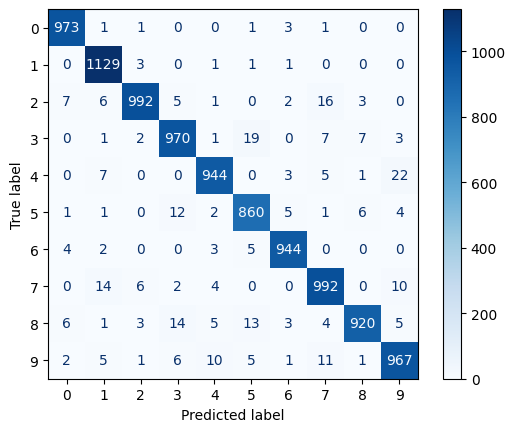

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, y_train)
pred = knn.predict(Xte)

print("accuracy:", accuracy_score(y_test, pred))
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.show()

Accuracy lands around 96%/97% for KNN on full MSNT and the confusion matrix can be read as rows are true digits, columns are predictions, the diagonal is correct, and off-diagonal cells are mistakes. The large values along the diagonal show the model classifies most digits correctly, while the small off-diagonal counts show where it confuses one digit for another. Overall accuracy is the sum of the diagonal divided by the total number of test images which amounts to 10000.

##Q6:


The most common mistake is a 4 being predicted as a 9, which happens 22 times. That makes sense, because a 4 written with a closed top looks a lot like a 9. Other frequent mistakes are 3 predicted as 5 (19), 2 as 7 (16), 8 as 3 (14), and 7 as 1 (14). Some mistakes only go one way: 7 is mistaken for 1 fourteen times, but 1 is never mistaken for 7. A sloppy 7 can look like a 1, but a simple straight 1 doesn't have enough strokes to look like a 7. The digit 8 is the messiest, with at least one error in every column of its row, since its loops overlap with the shapes of 3, 5, and 9. Meanwhile, 0, 1, and 6 are the easiest digits because their shapes are distinctive.

##Q7:

For a color photo, each pixel can be represented by three numbers instead of one. Its red, green, and blue (RGB) values, each ranging from 0 to 255. For example, pure red is (255, 0, 0) and white is (255, 255, 255). This means a color photo can be stored as three matrices stacked together, one for each color channel. MNIST is the simpler case, since each pixel only has a single value for how dark it is. To convert a set of photos into tabular data, we would first resize them all to the same dimensions, such as 64 x 64. Then we would flatten each photo into a single row, just as we did in Q3. Since each pixel now has three values, each row would have 64 x 64 x 3 = 12,288 columns. Each photo becomes one row, and adding a label column (such as "cat" or "dog") gives a standard dataset that kNN or any other model can be applied to.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]